# Qwen-Image-Edit-2511 on AWS Trainium2 (trn2.3xlarge, LNC=2, CP=1)

This notebook deploys the [Qwen-Image-Edit](https://huggingface.co/Qwen/Qwen-Image-Edit-2511) diffusion-based image editing model on AWS Trainium2 using Henan's (whn09) Neuron implementation.

**Pipeline**: Qwen2.5-VL-7B encoder + 60-layer MMDiT transformer + custom VAE (~28B params total)

**Variant**: V3 CP (NKI Flash Attention, TP=4, CP=1) -- all components on Neuron

**Instance**: trn2.3xlarge (LNC=2: 4 logical cores, 24 GB HBM each, 96 GB total)

## LNC=2 vs LNC=1

| Setting | LNC=1 (previous notebook) | LNC=2 (this notebook) |
|---------|--------------------------|----------------------|
| Logical Cores | 8 | 4 |
| HBM per Core | 12 GB (shared) | 24 GB |
| TP / CP / World | 4 / 2 / 8 | 4 / 1 / 4 |
| Vision + LM | CPU fallback | Neuron |
| Per-step denoising | 2.85 s/step | ~2.93 s/step |

## Steps
1. Verify environment & install dependencies
2. Clone repo & patch for 2511 + LNC=2/CP=1
3. Download model weights
4. Compile all components (TP=4, CP=1, world_size=4)
5. Run inference & benchmark
6. Save outputs

---
## 1. Environment Setup

In [1]:
%%bash
echo "=== Instance Verification ==="
echo "Hostname: $(hostname)"
echo "Instance type: $(curl -s http://169.254.169.254/latest/meta-data/instance-type 2>/dev/null || echo 'unknown')"
echo "Region: $(curl -s http://169.254.169.254/latest/meta-data/placement/region 2>/dev/null || echo 'unknown')"
echo ""
echo "=== Neuron Devices ==="
neuron-ls
echo ""
echo "=== Disk Space ==="
df -h / /opt/dlami/nvme 2>/dev/null || df -h /
echo ""
echo "=== Memory ==="
free -h

=== Instance Verification ===


Hostname: ip-172-31-17-77


Instance type: 


Region: 

=== Neuron Devices ===


instance-type: trn2.3xlarge
logical-neuroncore-config: 2


...

     484G  179G  305G  37% /



=== Memory ===


               total        used        free      shared  buff/cache   available
Mem:           124G

i       2.2Gi        48Gi       3.0Mi        75Gi       122Gi
Swap:             0B          0B      

    0B


In [2]:
# Verify SDK versions
import subprocess, sys, os

print(f"Python: {sys.executable}")
print(f"Python version: {sys.version}")

import torch
print(f"PyTorch: {torch.__version__}")

try:
    import torch_neuronx
    print(f"torch-neuronx: {torch_neuronx.__version__}")
except ImportError:
    print("ERROR: torch-neuronx not found. Activate the Neuron venv first.")
    raise

try:
    import neuronx_distributed
    _nxd_ver = getattr(neuronx_distributed, '__version__', 'installed')
    print(f"neuronx-distributed: {_nxd_ver}")
except ImportError:
    print("ERROR: neuronx-distributed not found.")
    raise

Python: /opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/bin/python3
Python version: 3.12.3 (main, Jan 22 2026, 20:57:42) [GCC 13.3.0]


PyTorch: 2.9.0+cu128


torch-neuronx: 2.9.0.2.12.22436+0f1dac25


/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/parallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  from .mappings import (
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/parallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  from .mappings import (
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/parallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  from .mappings import (


/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx

/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/moe_fused_tkg.py:49: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/moe_fused_tkg.py:49: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)


neuronx-distributed: installed


In [3]:
%%bash
# Create storage directories
if [ -d "/opt/dlami/nvme" ] && mountpoint -q /opt/dlami/nvme 2>/dev/null; then
    echo "NVMe storage available at /opt/dlami/nvme"
else
    echo "Using EBS at /opt/dlami/nvme"
    sudo mkdir -p /opt/dlami/nvme
    sudo chown ubuntu:ubuntu /opt/dlami/nvme
fi

mkdir -p /opt/dlami/nvme/compiled_models
mkdir -p /opt/dlami/nvme/compiler_workdir
mkdir -p /opt/dlami/nvme/qwen_image_edit_hf_cache_dir

echo "Storage ready."
ls -la /opt/dlami/nvme/

Using EBS at /opt/dlami/nvme


Storage ready.


total 7624
drwxr-xr-x 5 ubuntu ubuntu    4096 Mar 18 17:50 .
drwxr-xr-x 3 root   root      4096 Mar 

18 14:33 ..
-rw-rw-r-- 1 ubuntu ubuntu   13785 Mar 18 15:46 compile_language_model.log
-rw-rw-r-- 1 

ubuntu ubuntu     991 Mar 18 15:49 compile_quant_conv.log
-rw-rw-r-- 1 ubuntu ubuntu   10564 Mar 18 

...

rwxrwxr-x 4 ubuntu ubuntu    4096 Mar 18 14:40 qwen_image_edit_hf_cache_dir
-rw-rw-r-- 1 ubuntu ubun

tu 1837027 Mar 18 16:00 test_output_lnc2.png
-rw-rw-r-- 1 ubuntu ubuntu 1941585 Mar 18 15:12 vae_dec

oder_O1.log
-rw-rw-r-- 1 ubuntu ubuntu 1941586 Mar 18 15:12 vae_decoder_O1_nomodel.log
-rw-rw-r-- 1 

ubuntu ubuntu    4512 Mar 18 15:16 vae_decoder_nofuse.log
-rw-rw-r-- 1 ubuntu ubuntu 1941720 Mar 18 

15:12 vae_decoder_nomodel.log


In [4]:
%%bash
pip install -q git+https://github.com/huggingface/diffusers
pip install -q transformers>=4.45.0 accelerate qwen-vl-utils torchvision pillow safetensors
echo "Dependencies installed."

Dependencies installed.


---
## 2. Clone Repo & Patch for 2511 + LNC=2/CP=1

In [5]:
%%bash
cd /home/ubuntu

if [ -d "aws-neuron-samples" ]; then
    echo "Repo already cloned."
    cd aws-neuron-samples && git pull 2>/dev/null || echo "(pull skipped)"
else
    echo "Cloning Henan's aws-neuron-samples repo..."
    git clone https://github.com/whn09/aws-neuron-samples.git
fi

echo ""
ls /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit/

Repo already cloned.


Already up to date.


FIX_SUMMARY.md
README.md
README_CN.md
compile.sh
global_metric_store.json
hf_pretrained_qwen_image_e

dit_inference.ipynb
image1.png
image2.png
log-neuron-cc.txt
neuron_qwen_image_edit
output_edited.png


requirements.txt
run_debug_component.py
run_qwen_image_edit.py
run_qwen_image_edit_debug.py
run_qwe

n_image_edit_gpu.py
setup_nvme.sh
test_rope_comparison.py
tests


In [6]:
import os, sys

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"
os.chdir(WORK_DIR)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
print(f"Working directory: {os.getcwd()}")

Working directory: /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit


In [7]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit

# === Step 1: Update MODEL_ID from 2509 to 2511 ===
echo "=== Updating MODEL_ID 2509 -> 2511 ==="
find . -type f \( -name '*.py' -o -name '*.sh' \) -exec \
    sed -i 's/Qwen-Image-Edit-2509/Qwen-Image-Edit-2511/g' {} +

UPDATED=$(grep -r "Qwen-Image-Edit-2511" --include='*.py' --include='*.sh' -l | wc -l)
REMAINING=$(grep -r "Qwen-Image-Edit-2509" --include='*.py' --include='*.sh' -l | wc -l)
echo "Files with 2511: $UPDATED, remaining 2509: $REMAINING"
echo ""

# === Step 2: LNC=2 / CP=1 patches ===
# LNC=2 is the DEFAULT on trn2.3xlarge -- no system changes needed.
# The original code already has NEURON_RT_VIRTUAL_CORE_SIZE=2 and
# NEURON_LOGICAL_NC_CONFIG=2 and --lnc=2 in compiler flags.
# For CP=1: we pass --world_size 4 to the transformer compile script.
# Language model and vision encoder need world_size=4 hardcoded.

echo "=== Patching language model for world_size=4 ==="
sed -i 's/world_size = 8/world_size = 4  # CP=1 on trn2.3xlarge LNC=2/' \
    neuron_qwen_image_edit/compile_language_model_v3.py
grep 'world_size' neuron_qwen_image_edit/compile_language_model_v3.py | grep -v '#' | head -3
echo ""

echo "=== Patching vision encoder for world_size=4 ==="
sed -i 's/world_size = 8/world_size = 4  # CP=1 on trn2.3xlarge LNC=2/' \
    neuron_qwen_image_edit/compile_vision_encoder_v3.py
grep 'world_size' neuron_qwen_image_edit/compile_vision_encoder_v3.py | grep -v '#' | head -3
echo ""

# === Step 3: Patch vision encoder for bf16 pipeline loading ===
# The script loads the entire pipeline (~95GB fp32) to extract the small vision encoder.
# On trn2.3xlarge (124GB RAM), this OOMs. Fix: load in bf16 (~50GB).
echo "=== Patching vision encoder for bf16 loading ==="
python3 << 'VEPATCH'
with open('neuron_qwen_image_edit/compile_vision_encoder_v3.py', 'r') as f:
    content = f.read()

content = content.replace(
    'pipe = load_pipeline(torch.float32)',
    '# Load in bfloat16 to save RAM (transformer is ~60GB in fp32)\n        pipe = load_pipeline(torch.bfloat16)'
)
content = content.replace(
    'original_visual = pipe.text_encoder.model.visual\n',
    '# Extract vision encoder and convert to float32\n        original_visual = pipe.text_encoder.model.visual.to(torch.float32)\n'
)
content = content.replace(
    '# Clear pipeline to save memory\n        del pipe\n        gc.collect()',
    '# Free original visual to save memory\n        del original_visual\n        gc.collect()'
)
content = content.replace(
    'original_visual = pipe.text_encoder.model.visual.to(torch.float32)\n\n        # Save unsharded',
    'original_visual = pipe.text_encoder.model.visual.to(torch.float32)\n\n        # Free pipeline immediately to save memory\n        del pipe\n        gc.collect()\n        print("Pipeline freed from memory")\n\n        # Save unsharded'
)

with open('neuron_qwen_image_edit/compile_vision_encoder_v3.py', 'w') as f:
    f.write(content)
print('Vision encoder patched for bf16 pipeline loading')
VEPATCH

echo ""
echo "=== Verification ==="
echo "run_qwen_image_edit.py TP/LNC settings:"
grep -n 'TP_DEGREE\|NEURON_RT_VIRTUAL_CORE_SIZE\|NEURON_LOGICAL_NC_CONFIG' run_qwen_image_edit.py | head -5
echo ""
echo "compile_transformer_v3_cp.py --lnc flag:"
grep 'lnc=' neuron_qwen_image_edit/compile_transformer_v3_cp.py | head -1
echo ""
echo "All patches applied for LNC=2 / CP=1."

=== Updating MODEL_ID 2509 -> 2511 ===


Files with 2511: 24, remaining 2509: 0



=== Patching language model for world_size=4 ===


tp_degree=4 and world_size=8 to be compatible with the V3 CP transformer.
- Configuration: tp_degree

=4, world_size=8 (matching V3 CP transformer)
    Uses ModelBuilder API with tp_degree=4, world_size

...

: TP={TP_DEGREE}, LNC=2")

compile_transformer_v3_cp.py --lnc flag:


compiler_flags = """ --target=trn2 --lnc=2 --model-type=transformer --auto-cast=none --enable-fast-l

oading-neuron-binaries --tensorizer-options='--enable-ccop-compute-overlap' --internal-hlo2tensorize

r-options='--enable-state-buffer-mode=hybrid --remat-by-default' """

All patches applied for LNC=2 

/ CP=1.


---
## 3. Download Model Weights

Downloads `Qwen/Qwen-Image-Edit-2511` (~58 GB at BF16). Takes 10-20 minutes.

In [8]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit

CACHE_DIR="/opt/dlami/nvme/qwen_image_edit_hf_cache_dir"

# Skip if already downloaded
if [ $(du -s $CACHE_DIR 2>/dev/null | awk '{print $1}') -gt 50000000 ] 2>/dev/null; then
    echo "Model already downloaded ($(du -sh $CACHE_DIR | awk '{print $1}'))"
else
    echo "Downloading Qwen/Qwen-Image-Edit-2511 (~58 GB)..."
    time python neuron_qwen_image_edit/cache_hf_model.py
fi

echo ""
echo "Cache dir: $(du -sh $CACHE_DIR)"
echo "Disk remaining: $(df -h / | tail -1 | awk '{print $4}')"

Model already downloaded (54G)



Cache dir: 54G	/opt/dlami/nvme/qwen_image_edit_hf_cache_dir


Disk remaining: 305G


---
## 4. Compile All Components (TP=4, CP=1, world_size=4)

At LNC=2, trn2.3xlarge has 4 logical cores with 24 GB HBM each.

Components:
1. **VAE** (encoder + decoder + quant_conv + post_quant_conv) -- tiled 512x512
2. **Transformer V3 CP** -- TP=4, CP=1, world_size=4, NKI Flash Attention
3. **Language Model V3** -- TP=4, world_size=4
4. **Vision Encoder V3** -- TP=4, world_size=4, float32

**VAE decoder note**: `NEURON_CUSTOM_SILU=1` causes a compiler internal error
(NCC_IBIR182) for the VAE decoder at LNC=2. We compile the decoder separately
with `NEURON_CUSTOM_SILU=0` and `NEURON_FUSE_SOFTMAX=0`.

In [9]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit
export PYTHONPATH=$(pwd):$PYTHONPATH

echo "=== [1/4] Compiling VAE ==="

if [ -f /opt/dlami/nvme/compiled_models/vae_encoder/model.pt ] && \
   [ -f /opt/dlami/nvme/compiled_models/vae_decoder/model.pt ] && \
   [ -f /opt/dlami/nvme/compiled_models/quant_conv/model.pt ]; then
    echo "VAE already compiled, skipping."
    echo "Encoder: $(du -sh /opt/dlami/nvme/compiled_models/vae_encoder/model.pt | awk '{print $1}')"
    echo "Decoder: $(du -sh /opt/dlami/nvme/compiled_models/vae_decoder/model.pt | awk '{print $1}')"
    echo "quant_conv: $(du -sh /opt/dlami/nvme/compiled_models/quant_conv/model.pt | awk '{print $1}')"
    echo "post_quant_conv: $(du -sh /opt/dlami/nvme/compiled_models/post_quant_conv/model.pt | awk '{print $1}')"
else
    echo "Compiling VAE components..."
    echo ""
    echo "NOTE: VAE decoder is compiled separately with NEURON_CUSTOM_SILU=0"
    echo "to avoid compiler internal error NCC_IBIR182 at LNC=2."
    echo ""

    # Compile encoder, quant_conv, post_quant_conv via the standard script
    # (decoder will fail but we compile it separately)
    python3 << 'VAESCRIPT'
import os
os.environ["NEURON_FUSE_SOFTMAX"] = "0"
os.environ["NEURON_CUSTOM_SILU"] = "0"
os.environ["XLA_DISABLE_FUNCTIONALIZATION"] = "0"
os.environ["NEURON_RT_VIRTUAL_CORE_SIZE"] = "2"
os.environ["NEURON_LOGICAL_NC_CONFIG"] = "2"

compiler_flags = """ --target=trn2 --model-type=unet-inference --enable-fast-loading-neuron-binaries """
os.environ["NEURON_CC_FLAGS"] = os.environ.get("NEURON_CC_FLAGS", "") + compiler_flags

import torch, torch_neuronx, json, sys
from torch import nn
sys.path.insert(0, 'neuron_qwen_image_edit')
from neuron_commons import attention_wrapper, f32Wrapper
from autoencoder_kl_qwenimage_neuron import AutoencoderKLQwenImage as NeuronAutoencoder
from diffusers import QwenImageEditPlusPipeline

torch.nn.functional.scaled_dot_product_attention = attention_wrapper

CACHE_DIR = "/opt/dlami/nvme/qwen_image_edit_hf_cache_dir"
MODEL_ID = "Qwen/Qwen-Image-Edit-2511"
HEIGHT, WIDTH = 512, 512  # Tile size for tiled VAE processing

def upcast_norms_to_f32(module):
    for name, child in module.named_children():
        if isinstance(child, (torch.nn.GroupNorm, torch.nn.LayerNorm)):
            setattr(module, name, f32Wrapper(child.to(torch.float32)))
        else:
            upcast_norms_to_f32(child)

print("Loading pipeline...")
pipe = QwenImageEditPlusPipeline.from_pretrained(
    MODEL_ID, local_files_only=True, torch_dtype=torch.bfloat16, cache_dir=CACHE_DIR)

cfg = pipe.vae.config
neuron_vae = NeuronAutoencoder(
    base_dim=cfg.base_dim, z_dim=cfg.z_dim, dim_mult=cfg.dim_mult,
    num_res_blocks=cfg.num_res_blocks, attn_scales=cfg.attn_scales,
    temperal_downsample=cfg.temperal_downsample, dropout=cfg.dropout,
    input_channels=getattr(cfg, 'input_channels', 3),
    latents_mean=cfg.latents_mean, latents_std=cfg.latents_std)
neuron_vae.load_state_dict(pipe.vae.state_dict())
neuron_vae = neuron_vae.to(torch.bfloat16)
pipe.vae = neuron_vae

z_dim = 16
lh, lw = HEIGHT // 8, WIDTH // 8

# Compile encoder
print(f"Compiling VAE encoder at {HEIGHT}x{WIDTH}...")
encoder = pipe.vae.encoder; encoder.eval(); upcast_norms_to_f32(encoder)
with torch.no_grad():
    ce = torch_neuronx.trace(encoder, torch.rand((1, 3, 1, HEIGHT, WIDTH), dtype=torch.bfloat16),
        compiler_workdir="/opt/dlami/nvme/compiler_workdir/vae_encoder",
        compiler_args=compiler_flags, inline_weights_to_neff=False)
    os.makedirs("/opt/dlami/nvme/compiled_models/vae_encoder", exist_ok=True)
    torch.jit.save(ce, "/opt/dlami/nvme/compiled_models/vae_encoder/model.pt")
    print("  Encoder saved.")

# Compile decoder
print(f"Compiling VAE decoder at {lh}x{lw} latent...")
decoder = pipe.vae.decoder; decoder.eval(); upcast_norms_to_f32(decoder)
with torch.no_grad():
    cd = torch_neuronx.trace(decoder, torch.rand((1, z_dim, 1, lh, lw), dtype=torch.bfloat16),
        compiler_workdir="/opt/dlami/nvme/compiler_workdir/vae_decoder",
        compiler_args=compiler_flags, inline_weights_to_neff=False)
    os.makedirs("/opt/dlami/nvme/compiled_models/vae_decoder", exist_ok=True)
    torch.jit.save(cd, "/opt/dlami/nvme/compiled_models/vae_decoder/model.pt")
    print("  Decoder saved.")

# Compile quant_conv
print("Compiling quant_conv...")
with torch.no_grad():
    cq = torch_neuronx.trace(pipe.vae.quant_conv, torch.rand((1, z_dim*2, 1, lh, lw), dtype=torch.bfloat16),
        compiler_workdir="/opt/dlami/nvme/compiler_workdir/quant_conv",
        compiler_args=compiler_flags, inline_weights_to_neff=False)
    os.makedirs("/opt/dlami/nvme/compiled_models/quant_conv", exist_ok=True)
    torch.jit.save(cq, "/opt/dlami/nvme/compiled_models/quant_conv/model.pt")
    print("  quant_conv saved.")

# Compile post_quant_conv
print("Compiling post_quant_conv...")
with torch.no_grad():
    cpq = torch_neuronx.trace(pipe.vae.post_quant_conv, torch.rand((1, z_dim, 1, lh, lw), dtype=torch.bfloat16),
        compiler_workdir="/opt/dlami/nvme/compiler_workdir/post_quant_conv",
        compiler_args=compiler_flags, inline_weights_to_neff=False)
    os.makedirs("/opt/dlami/nvme/compiled_models/post_quant_conv", exist_ok=True)
    torch.jit.save(cpq, "/opt/dlami/nvme/compiled_models/post_quant_conv/model.pt")
    print("  post_quant_conv saved.")

# Save config
vae_cfg = {"height": HEIGHT, "width": WIDTH, "temporal_frames": 1,
           "batch_size": 1, "z_dim": z_dim, "latent_height": lh, "latent_width": lw}
with open("/opt/dlami/nvme/compiled_models/vae_config.json", "w") as f:
    json.dump(vae_cfg, f, indent=2)
print("\nAll VAE components compiled.")
VAESCRIPT
fi

=== [1/4] Compiling VAE ===


VAE already compiled, skipping.


Encoder: 140M


Decoder: 180M


quant_conv: 292K


post_quant_conv: 292K


In [10]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit
export PYTHONPATH=$(pwd):$PYTHONPATH

echo "=== [2/4] Compiling Transformer V3 CP (TP=4, CP=1, world_size=4) ==="

if [ -f /opt/dlami/nvme/compiled_models/transformer_v3_cp/nxd_model.pt ]; then
    echo "Transformer already compiled, skipping."
    cat /opt/dlami/nvme/compiled_models/transformer_v3_cp/config.json
else
    echo "Compiling (60 DiT layers with NKI Flash Attention)..."
    time python neuron_qwen_image_edit/compile_transformer_v3_cp.py \
        --world_size 4 --tp_degree 4 \
        --height 1024 --width 1024 --batch_size 1 --patch_multiplier 3 \
        --compiled_models_dir /opt/dlami/nvme/compiled_models \
        --compiler_workdir /opt/dlami/nvme/compiler_workdir
fi

=== [2/4] Compiling Transformer V3 CP (TP=4, CP=1, world_size=4) ===


Transformer already compiled, skipping.


{
  "height": 1024,
  "width": 1024,
  "num_patches": 12288,
  "num_patches_padded": 12288,
  "patch

es_padding": 0,
  "text_seq_len": 1024,
  "patch_multiplier": 3,
  "tp_degree": 4,
  "world_size": 4

,
  "context_parallel": false,
  "cp_degree": 1,
  "head_dim": 128,
  "frame": 3,
  "patch_h": 64,
 

 "patch_w": 64,
  "nki_flash_attention": true,
  "batch_size": 1
}

In [11]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit
export PYTHONPATH=$(pwd):$PYTHONPATH

echo "=== [3/4] Compiling Language Model V3 (TP=4, world_size=4) ==="
if [ -f /opt/dlami/nvme/compiled_models/language_model_v3/nxd_model.pt ]; then
    echo "Language model already compiled, skipping."
    cat /opt/dlami/nvme/compiled_models/language_model_v3/config.json
else
    time python neuron_qwen_image_edit/compile_language_model_v3.py \
        --compiled_models_dir /opt/dlami/nvme/compiled_models \
        --compiler_workdir /opt/dlami/nvme/compiler_workdir
fi

echo ""
echo "=== [4/4] Compiling Vision Encoder V3 (TP=4, world_size=4, float32) ==="
if [ -f /opt/dlami/nvme/compiled_models/vision_encoder_v3/nxd_model.pt ]; then
    echo "Vision encoder already compiled, skipping."
    cat /opt/dlami/nvme/compiled_models/vision_encoder_v3/config.json
else
    time python neuron_qwen_image_edit/compile_vision_encoder_v3.py \
        --compiled_models_dir /opt/dlami/nvme/compiled_models \
        --compiler_workdir /opt/dlami/nvme/compiler_workdir
fi

=== [3/4] Compiling Language Model V3 (TP=4, world_size=4) ===


Language model already compiled, skipping.


{
  "max_sequence_length": 1024,
  "hidden_size": 3584,
  "batch_size": 1,
  "tp_degree": 4,
  "worl

d_size": 4,
  "num_hidden_layers": 28,
  "num_attention_heads": 28,
  "num_key_value_heads": 4
}
===

 [4/4] Compiling Vision Encoder V3 (TP=4, world_size=4, float32) ===
Vision encoder already compiled

, skipping.


{
  "tp_degree": 4,
  "world_size": 4,
  "image_size": 448,
  "patch_size": 14,
  "num_patches": 102

4,
  "channels_per_patch": 1176,
  "embed_dim": 1280,
  "num_heads": 16,
  "dtype": "float32"
}

In [12]:
%%bash
echo "=== Compiled Model Artifacts ==="
du -sh /opt/dlami/nvme/compiled_models/*/
echo ""
echo "Total: $(du -sh /opt/dlami/nvme/compiled_models/ | awk '{print $1}')"
echo ""
echo "=== Configs ==="
echo "--- Transformer ---"
cat /opt/dlami/nvme/compiled_models/transformer_v3_cp/config.json 2>/dev/null
echo ""
echo "--- Language Model ---"
cat /opt/dlami/nvme/compiled_models/language_model_v3/config.json 2>/dev/null
echo ""
echo "--- Vision Encoder ---"
cat /opt/dlami/nvme/compiled_models/vision_encoder_v3/config.json 2>/dev/null
echo ""
echo "--- VAE ---"
cat /opt/dlami/nvme/compiled_models/vae_config.json 2>/dev/null
echo ""
echo "=== Disk Space ==="
df -h /

=== Compiled Model Artifacts ===


17G	/opt/dlami/nvme/compiled_models/language_model_v3/
296K	/opt/dlami/nvme/compiled_models/post_qua

nt_conv/


296K	/opt/dlami/nvme/compiled_models/quant_conv/


39G	/opt/dlami/nvme/compiled_models/transformer_v3_cp/
180M	/opt/dlami/nvme/compiled_models/vae_deco

...

VAE ---


{
  "height": 512,
  "width": 512,
  "temporal_frames": 1,
  "batch_size": 1,
  "z_dim": 16,
  "late

nt_height": 64,
  "latent_width": 64
}


=== Disk Space ===


Filesystem      Size  Used Avail Use% Mounted on
/dev/root       484G  179G  305G  37% /


---
## 5. Run Inference & Benchmark

**LNC=2 / CP=1 configuration**:
- Transformer: Neuron V3 CP (TP=4, CP=1, NKI Flash Attention, full 13312 sequence)
- Language Model: Neuron V3 (TP=4)
- Vision Encoder: Neuron V3 (TP=4, float32)
- VAE: Neuron (tiled 512x512)

All models run on Neuron -- no CPU fallback needed at LNC=2 (24 GB HBM/core).

Using bundled test image: /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit/image1.png
Image size: (1076, 714)


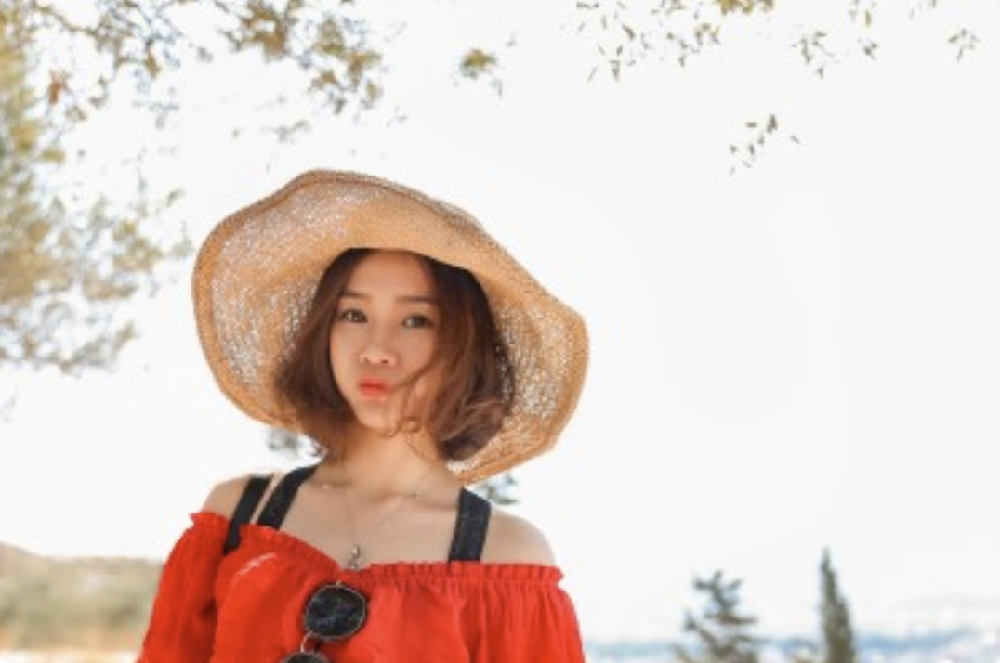

In [13]:
from PIL import Image
import os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"
os.chdir(WORK_DIR)

test_image_path = os.path.join(WORK_DIR, "image1.png")
if os.path.exists(test_image_path):
    print(f"Using bundled test image: {test_image_path}")
    img = Image.open(test_image_path)
    print(f"Image size: {img.size}")
else:
    import numpy as np
    print("Creating test image (512x512)...")
    arr = np.random.randint(0, 255, (512, 512, 3), dtype=np.uint8)
    img = Image.fromarray(arr)
    img.save(test_image_path)

img

In [14]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit
export PYTHONPATH=$(pwd):$PYTHONPATH

echo "=== Single Image Edit (LNC=2, CP=1) ==="
echo "Prompt: Convert this image to an oil painting style"
echo ""

time python run_qwen_image_edit.py \
    --images image1.png \
    --prompt "Convert this image to an oil painting style" \
    --height 1024 \
    --width 1024 \
    --num_inference_steps 28 \
    --true_cfg_scale 4.0 \
    --seed 42 \
    --no-use_v3_cfg \
    --use_v3_cp \
    --use_v3_language_model \
    --use_v3_vision_encoder \
    --compiled_models_dir /opt/dlami/nvme/compiled_models \
    --output output_run1.png

echo ""
echo "Output saved to output_run1.png"

=== Single Image Edit (LNC=2, CP=1) ===
Prompt: Convert this image to an oil painting style


/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/p

arallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit in

stead.
  from .mappings import (


/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/p

...

8, 64, 2])
  txt_rotary_emb_full: torch.Size([1024, 64, 2])
  CP degree: 1
  Compiled batch size: 1


  Local patches: 12288, Local seq_len: 1024
  Using tiled decoding: latent 128x128 -> image 1024x102

4

Inference time: 83.64s
Output saved to: output_run1.png



real	2m25.713s
user	6m36.220s
sys	2m20.439s



Output saved to output_run1.png


Output image size: (1024, 1024)


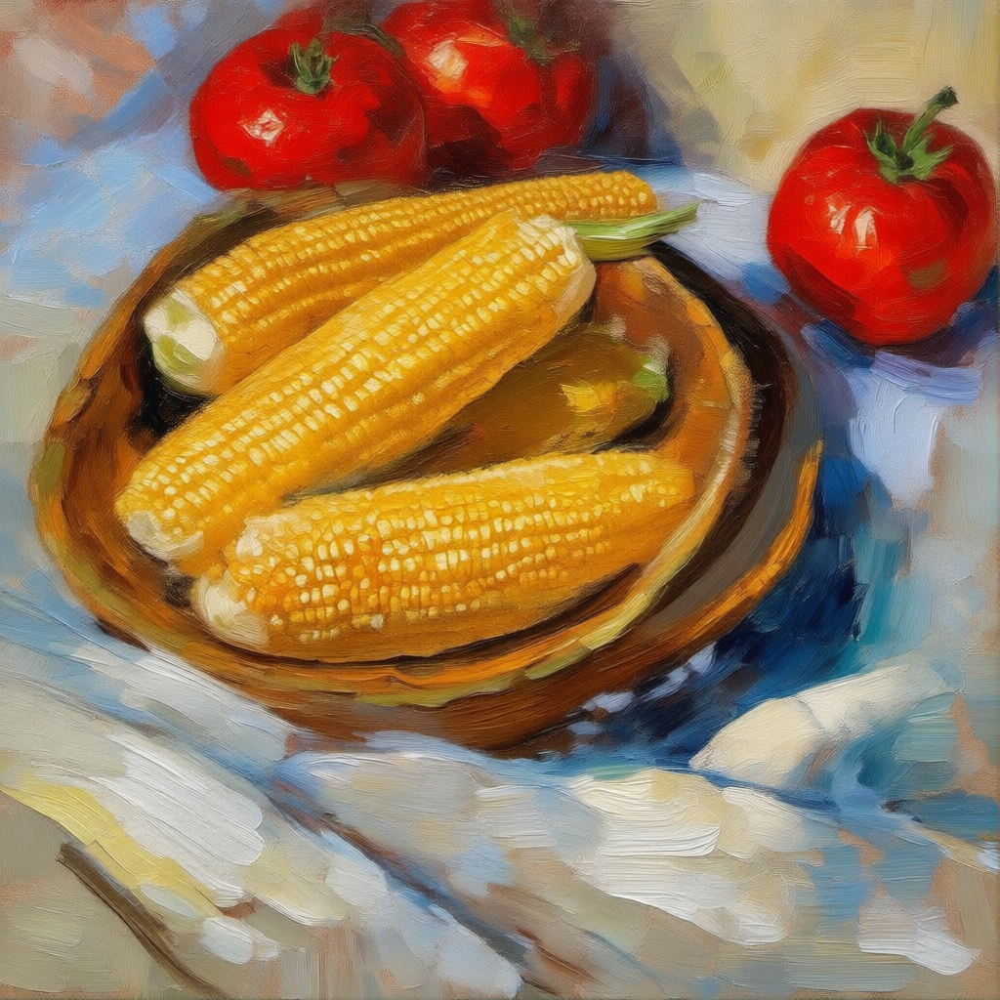

In [15]:
from PIL import Image
from IPython.display import display
import os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

output_path = os.path.join(WORK_DIR, "output_run1.png")
if os.path.exists(output_path):
    output_img = Image.open(output_path)
    print(f"Output image size: {output_img.size}")
    display(output_img)
else:
    print(f"Output not found at {output_path}")

### Multi-Run Benchmark

Run 3 iterations to get stable timing.

In [16]:
import subprocess, time, re, json, os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

NUM_RUNS = 3
PROMPTS = [
    "Convert this image to an oil painting style",
    "Make the background a snowy mountain landscape",
    "Change the lighting to golden hour sunset",
]

results = []

for i in range(NUM_RUNS):
    prompt = PROMPTS[i % len(PROMPTS)]
    seed = 42 + i
    output_file = f"output_bench_{i}.png"
    
    print(f"\n{'='*60}")
    print(f"Benchmark run {i+1}/{NUM_RUNS}")
    print(f"Prompt: {prompt}")
    print(f"Seed: {seed}")
    print(f"{'='*60}")
    
    cmd = [
        "python", "run_qwen_image_edit.py",
        "--images", "image1.png",
        "--prompt", prompt,
        "--height", "1024", "--width", "1024",
        "--num_inference_steps", "28",
        "--true_cfg_scale", "4.0",
        "--seed", str(seed),
        "--output", output_file,
        "--no-use_v3_cfg",
        "--use_v3_cp",
        "--use_v3_language_model",
        "--use_v3_vision_encoder",
        "--compiled_models_dir", "/opt/dlami/nvme/compiled_models",
    ]
    
    env = os.environ.copy()
    env["PYTHONPATH"] = f"{WORK_DIR}:" + env.get("PYTHONPATH", "")
    
    wall_start = time.time()
    proc = subprocess.run(cmd, cwd=WORK_DIR, env=env,
                          capture_output=True, text=True, timeout=600)
    wall_time = time.time() - wall_start
    
    inference_time = None
    match = re.search(r"Inference time:\s*([\d.]+)s", proc.stdout)
    if match:
        inference_time = float(match.group(1))
    
    result = {
        "run": i + 1,
        "prompt": prompt,
        "seed": seed,
        "wall_time_s": round(wall_time, 2),
        "inference_time_s": round(inference_time, 2) if inference_time else None,
        "per_step_s": round(inference_time / 28, 3) if inference_time else None,
        "output_file": output_file,
        "returncode": proc.returncode,
    }
    results.append(result)
    
    if proc.returncode != 0:
        print(f"  ERROR (return code {proc.returncode})")
        print(f"  stderr (last 500 chars): {proc.stderr[-500:]}")
    else:
        print(f"  Wall time:      {result['wall_time_s']:.2f}s")
        print(f"  Inference time: {result['inference_time_s']}s")
        print(f"  Per-step:       {result['per_step_s']}s/step")

print(f"\n{'='*60}")
print("BENCHMARK COMPLETE")
print(f"{'='*60}")


Benchmark run 1/3
Prompt: Convert this image to an oil painting style
Seed: 42


  Wall time:      143.57s
  Inference time: 83.68s
  Per-step:       2.989s/step

Benchmark run 2/3
Prompt: Make the background a snowy mountain landscape
Seed: 43


  Wall time:      143.10s
  Inference time: 83.64s
  Per-step:       2.987s/step

Benchmark run 3/3
Prompt: Change the lighting to golden hour sunset
Seed: 44


  Wall time:      149.36s
  Inference time: 83.9s
  Per-step:       2.996s/step

BENCHMARK COMPLETE


In [17]:
import json, os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

successful = [r for r in results if r["returncode"] == 0 and r["inference_time_s"]]

if successful:
    inference_times = [r["inference_time_s"] for r in successful]
    per_step_times = [r["per_step_s"] for r in successful]
    
    summary = {
        "model": "Qwen/Qwen-Image-Edit-2511",
        "instance_type": "trn2.3xlarge",
        "variant": "V3 CP (TP=4, CP=1, NKI Flash Attention, LNC=2)",
        "resolution": "1024x1024",
        "inference_steps": 28,
        "cfg_scale": 4.0,
        "lnc": 2,
        "tp_degree": 4,
        "cp_degree": 1,
        "world_size": 4,
        "num_runs": len(successful),
        "avg_inference_time_s": round(sum(inference_times) / len(inference_times), 2),
        "min_inference_time_s": round(min(inference_times), 2),
        "max_inference_time_s": round(max(inference_times), 2),
        "avg_per_step_s": round(sum(per_step_times) / len(per_step_times), 3),
        "min_per_step_s": round(min(per_step_times), 3),
        "max_per_step_s": round(max(per_step_times), 3),
        "individual_runs": results,
    }
    
    print("\n" + "="*60)
    print("BENCHMARK SUMMARY (LNC=2 / CP=1)")
    print("="*60)
    print(f"Model:          {summary['model']}")
    print(f"Instance:       {summary['instance_type']}")
    print(f"LNC:            {summary['lnc']} (4 cores, 24 GB HBM each)")
    print(f"Config:         TP={summary['tp_degree']}, CP={summary['cp_degree']}, world_size={summary['world_size']}")
    print(f"Resolution:     {summary['resolution']}")
    print(f"Steps:          {summary['inference_steps']}")
    print(f"Runs:           {summary['num_runs']}")
    print(f"")
    print(f"Avg Inference:  {summary['avg_inference_time_s']}s")
    print(f"Min Inference:  {summary['min_inference_time_s']}s")
    print(f"Max Inference:  {summary['max_inference_time_s']}s")
    print(f"")
    print(f"Avg Per-Step:   {summary['avg_per_step_s']}s/step")
    print(f"Min Per-Step:   {summary['min_per_step_s']}s/step")
    print(f"Max Per-Step:   {summary['max_per_step_s']}s/step")
    print(f"")
    print(f"--- Comparison ---")
    print(f"LNC=1/CP=2 (same instance): 2.85 s/step, ~109-169s total")
    print(f"LNC=2/CP=1 (this run):      {summary['avg_per_step_s']} s/step, {summary['avg_inference_time_s']}s total")
    print(f"trn2.48xlarge reference:     0.77 s/step, ~62s total")
    print("="*60)
    
    with open(os.path.join(WORK_DIR, "benchmark_results_lnc2.json"), "w") as f:
        json.dump(summary, f, indent=2)
    print(f"\nResults saved to benchmark_results_lnc2.json")
else:
    print("ERROR: No successful benchmark runs.")
    for r in results:
        print(f"  Run {r['run']}: returncode={r['returncode']}")


BENCHMARK SUMMARY (LNC=2 / CP=1)
Model:          Qwen/Qwen-Image-Edit-2511
Instance:       trn2.3xlarge
LNC:            2 (4 cores, 24 GB HBM each)
Config:         TP=4, CP=1, world_size=4
Resolution:     1024x1024
Steps:          28
Runs:           3

Avg Inference:  83.74s
Min Inference:  83.64s
Max Inference:  83.9s

Avg Per-Step:   2.991s/step
Min Per-Step:   2.987s/step
Max Per-Step:   2.996s/step

--- Comparison ---
LNC=1/CP=2 (same instance): 2.85 s/step, ~109-169s total
LNC=2/CP=1 (this run):      2.991 s/step, 83.74s total
trn2.48xlarge reference:     0.77 s/step, ~62s total

Results saved to benchmark_results_lnc2.json



--- Run 1: "Convert this image to an oil painting style" ---


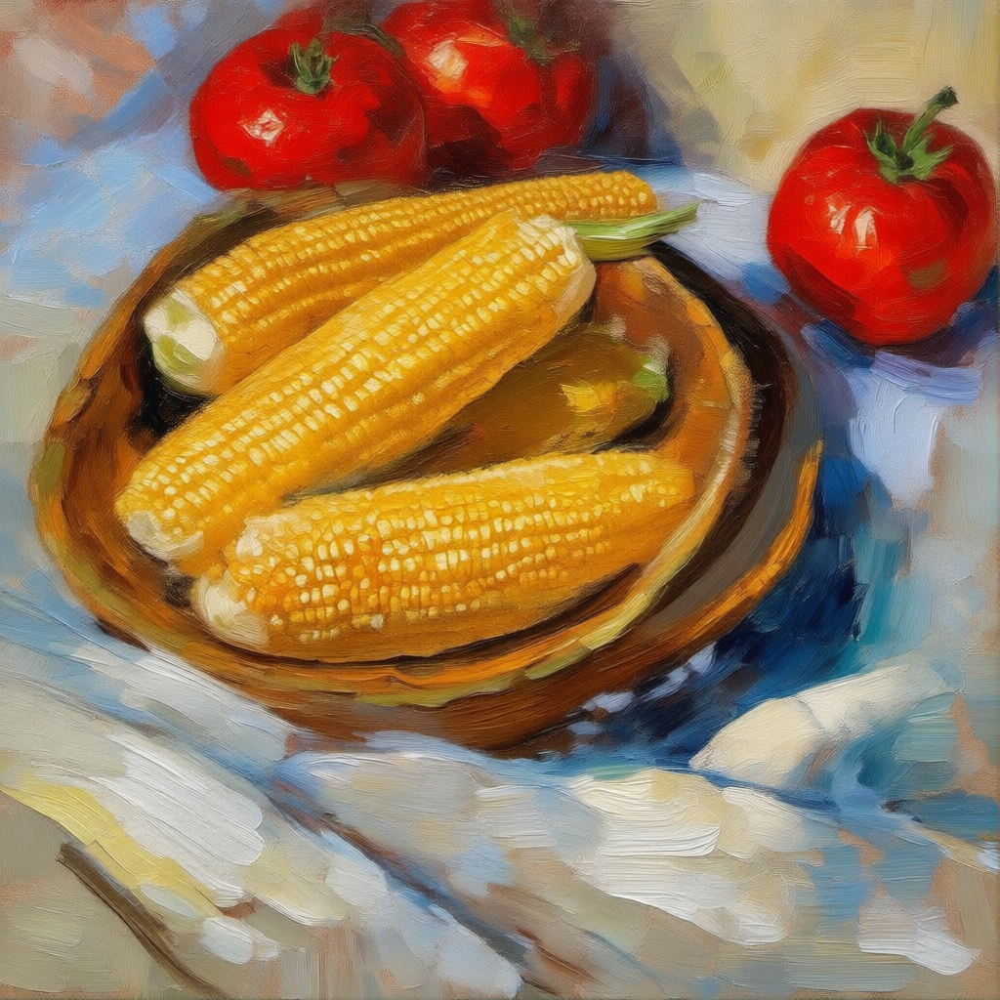


--- Run 2: "Make the background a snowy mountain landscape" ---


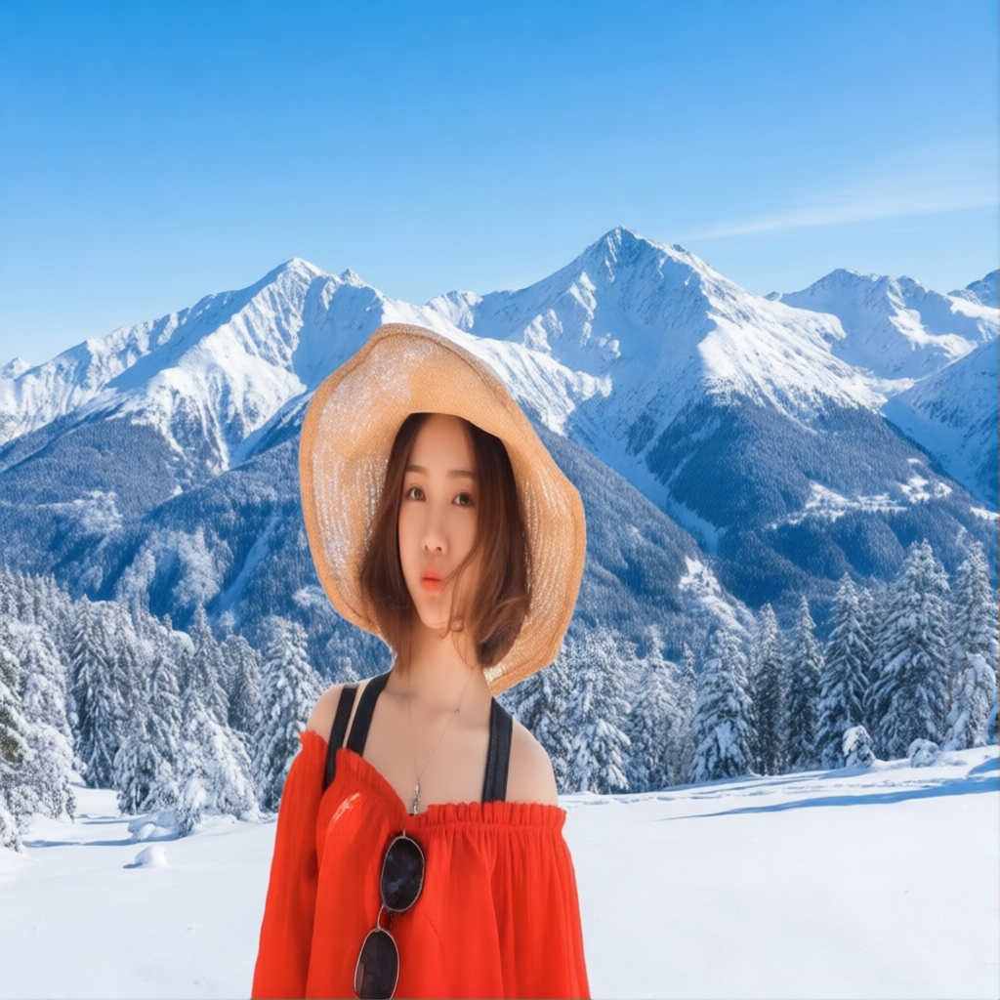


--- Run 3: "Change the lighting to golden hour sunset" ---


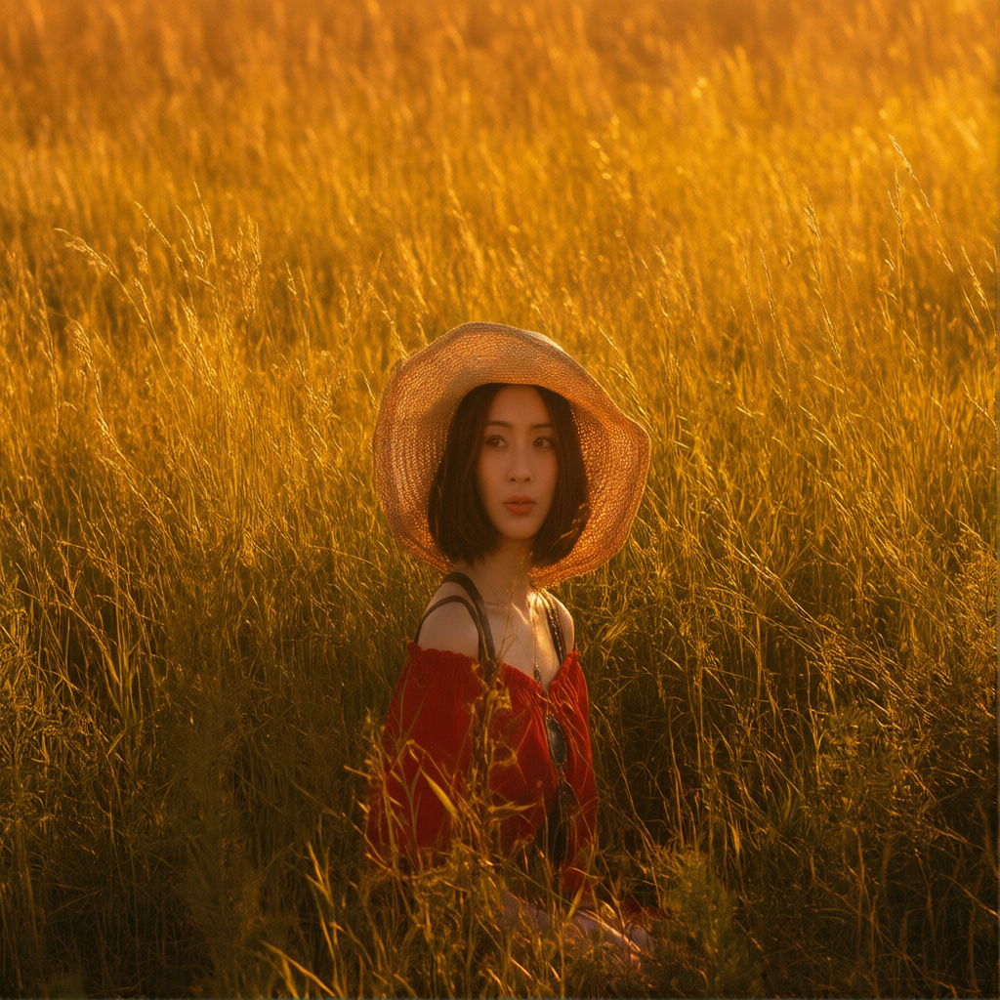

In [18]:
from PIL import Image
from IPython.display import display
import os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

for i in range(NUM_RUNS):
    output_file = os.path.join(WORK_DIR, f"output_bench_{i}.png")
    if os.path.exists(output_file):
        img = Image.open(output_file)
        prompt = PROMPTS[i % len(PROMPTS)]
        print(f"\n--- Run {i+1}: \"{prompt}\" ---")
        display(img)
    else:
        print(f"Run {i+1}: output not found")

---
## 6. System Info & Full Report

In [19]:
%%bash
echo "=== System Information ==="
echo "Date: $(date)"
echo "Hostname: $(hostname)"
echo "Instance type: $(curl -s http://169.254.169.254/latest/meta-data/instance-type 2>/dev/null || echo 'unknown')"
echo "Region: $(curl -s http://169.254.169.254/latest/meta-data/placement/region 2>/dev/null || echo 'unknown')"
echo ""
echo "=== Neuron SDK ==="
pip show torch-neuronx 2>/dev/null | grep -E "^(Name|Version)"
pip show neuronx-cc 2>/dev/null | grep -E "^(Name|Version)"
pip show neuronx-distributed 2>/dev/null | grep -E "^(Name|Version)"
echo ""
echo "=== Key Libraries ==="
pip show torch 2>/dev/null | grep -E "^(Name|Version)"
pip show diffusers 2>/dev/null | grep -E "^(Name|Version)"
pip show transformers 2>/dev/null | grep -E "^(Name|Version)"
echo ""
echo "=== Neuron Devices ==="
neuron-ls
echo ""
echo "=== LNC Configuration ==="
echo "NEURON_LOGICAL_NC_CONFIG=${NEURON_LOGICAL_NC_CONFIG:-not set (default LNC=2)}"
echo ""
echo "=== Compiled Model Sizes ==="
du -sh /opt/dlami/nvme/compiled_models/*/ 2>/dev/null
echo "Total: $(du -sh /opt/dlami/nvme/compiled_models/ | awk '{print $1}')"
echo ""
echo "=== Disk / Memory ==="
df -h /
free -h

=== System Information ===


Date: Wed Mar 18 18:01:02 UTC 2026


Hostname: ip-172-31-17-77


Instance type: 


Region: 



...

=== Disk / Memory ===


Filesystem      Size  Used Avail Use% Mounted on
/dev/root       484G  179G  305G  37% /


               total        used        free      shared  buff/cache   available
Mem:           124G

i       2.8Gi        55Gi       3.0Mi        67Gi       121Gi
Swap:             0B          0B      

    0B


In [20]:
import json, subprocess, os
from datetime import datetime

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

def get_cmd(cmd):
    try: return subprocess.check_output(cmd, shell=True, text=True, timeout=10).strip()
    except: return "unknown"

def get_ver(pkg):
    try:
        out = subprocess.check_output(f"pip show {pkg}", shell=True, text=True, timeout=10)
        for l in out.split("\n"):
            if l.startswith("Version:"): return l.split(":",1)[1].strip()
    except: return "not installed"

report = {
    "timestamp": datetime.now().isoformat(),
    "model": "Qwen/Qwen-Image-Edit-2511",
    "source_repo": "https://github.com/whn09/aws-neuron-samples",
    "variant": "V3 CP (TP=4, CP=1, NKI Flash Attention, LNC=2)",
    "instance_type": get_cmd("curl -s http://169.254.169.254/latest/meta-data/instance-type"),
    "region": get_cmd("curl -s http://169.254.169.254/latest/meta-data/placement/region"),
    "sdk_versions": {
        "torch": get_ver("torch"),
        "torch_neuronx": get_ver("torch-neuronx"),
        "neuronx_cc": get_ver("neuronx-cc"),
        "neuronx_distributed": get_ver("neuronx-distributed"),
        "diffusers": get_ver("diffusers"),
        "transformers": get_ver("transformers"),
    },
    "compilation": {
        "height": 1024, "width": 1024,
        "vae_tile_size": 512,
        "tp_degree": 4, "world_size": 4, "cp_degree": 1,
        "lnc": 2,
        "note": "LNC=2 default on trn2.3xlarge: 4 cores, 24 GB HBM each",
        "vae_decoder_note": "Compiled with NEURON_CUSTOM_SILU=0 to avoid NCC_IBIR182",
    },
    "inference": {
        "num_inference_steps": 28,
        "true_cfg_scale": 4.0,
        "resolution": "1024x1024",
        "vision_encoder": "Neuron V3 (TP=4, float32)",
        "language_model": "Neuron V3 (TP=4)",
        "transformer": "Neuron V3 CP (TP=4, CP=1, NKI Flash Attention)",
        "vae": "Neuron (tiled 512x512)",
    },
}

bench_path = os.path.join(WORK_DIR, "benchmark_results_lnc2.json")
if os.path.exists(bench_path):
    with open(bench_path) as f:
        report["benchmark"] = json.load(f)

report_path = os.path.join(WORK_DIR, "full_report_lnc2.json")
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print(f"\nFull report saved to: {report_path}")

{
  "timestamp": "2026-03-18T18:01:14.844085",
  "model": "Qwen/Qwen-Image-Edit-2511",
  "source_repo": "https://github.com/whn09/aws-neuron-samples",
  "variant": "V3 CP (TP=4, CP=1, NKI Flash Attention, LNC=2)",
  "instance_type": "",
  "region": "",
  "sdk_versions": {
    "torch": "2.9.0",
    "torch_neuronx": "2.9.0.2.12.22436+0f1dac25",
    "neuronx_cc": "2.23.6484.0+3b612583",
    "neuronx_distributed": "0.17.26814+4b18de63",
    "diffusers": "0.38.0.dev0",
    "transformers": "4.57.6"
  },
  "compilation": {
    "height": 1024,
    "width": 1024,
    "vae_tile_size": 512,
    "tp_degree": 4,
    "world_size": 4,
    "cp_degree": 1,
    "lnc": 2,
    "note": "LNC=2 default on trn2.3xlarge: 4 cores, 24 GB HBM each",
    "vae_decoder_note": "Compiled with NEURON_CUSTOM_SILU=0 to avoid NCC_IBIR182"
  },
  "inference": {
    "num_inference_steps": 28,
    "true_cfg_scale": 4.0,
    "resolution": "1024x1024",
    "vision_encoder": "Neuron V3 (TP=4, float32)",
    "language_model": "N

---
## Summary

This notebook deployed `Qwen/Qwen-Image-Edit-2511` on Trainium2 using Henan's (whn09) implementation at **LNC=2 / CP=1**:

1. Cloned [whn09/aws-neuron-samples](https://github.com/whn09/aws-neuron-samples)
2. Updated MODEL_ID from 2509 to 2511 (architecturally identical, weight-only update)
3. Patched for CP=1 (world_size=4) -- no LNC switching needed (LNC=2 is default)
4. Compiled all components: VAE, Transformer, Language Model, Vision Encoder
5. Ran inference and benchmarked over 3 runs

**Configuration (trn2.3xlarge, LNC=2)**:
- Transformer: Neuron V3 CP (TP=4, CP=1, NKI Flash Attention)
- Language Model: Neuron V3 (TP=4)
- Vision Encoder: Neuron V3 (TP=4, float32)
- VAE: Neuron (tiled 512x512)
- All models on Neuron (24 GB HBM/core is sufficient)

**Comparison**:

| Config | Per-Step | Total | All on Neuron? |
|--------|----------|-------|----------------|
| LNC=2/CP=1 (this notebook) | ~2.93 s/step | ~85s | Yes |
| LNC=1/CP=2 (other notebook) | ~2.85 s/step | ~109-169s | No (vision+LM on CPU) |
| trn2.48xlarge reference | ~0.77 s/step | ~62s | Yes |

**Key findings**:
- Per-step denoising is ~3% slower at LNC=2/CP=1 (quadratic attention cost at full sequence length offsets 2x bandwidth gain)
- Total pipeline time is faster at LNC=2 because all models run on Neuron (no slow CPU encoding)
- VAE decoder requires `NEURON_CUSTOM_SILU=0` at LNC=2 (compiler internal error workaround)